In [102]:
import pandas as pd

# volvemos a cargar el dataset completo
df = pd.read_csv("listings.csv")

# recreamos la columna de precio limpia (texto -> número)
df['price_clean'] = df['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

# recreamos el límite del IQR
q1 = df['price_clean'].quantile(0.25)
q3 = df['price_clean'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

# separamos las filas que superan ese límite
outliers = df[df['price_clean'] > limite_superior]
outliers_ordenados = outliers.sort_values('price_clean', ascending=False)

print(f"{len(outliers)} outliers de {len(df)} filas totales")

1410 outliers de 19187 filas totales


In [103]:
# pd.cut() agrupa los precios en "cajones" (buckets) según rangos que definimos nosotras
# así vemos cuántas filas caen en cada rango, en vez de mirar solo 20 a la vez
cajones = pd.cut(
    outliers['price_clean'],
    bins=[410000, 500000, 1_000_000, 5_000_000, 20_000_000, 100_000_000, 500_000_000],
    labels=['410K-500K', '500K-1M', '1M-5M', '5M-20M', '20M-100M', '100M+']
)

# .value_counts() cuenta cuántas filas cayeron en cada cajón
# sort_index=False mantiene el orden de los rangos, no de mayor a menor cantidad
print(cajones.value_counts(sort=False))

price_clean
410K-500K    475
500K-1M      630
1M-5M        267
5M-20M        20
20M-100M       5
100M+         13
Name: count, dtype: int64


In [104]:
# filtramos solo las filas realmente extremas: más de 5 millones COP/noche
extremos = outliers_ordenados[outliers_ordenados['price_clean'] > 5_000_000]

# mostramos nombre, precio y barrio para cada una - así vemos si hay algún patrón
# (ej. todas del mismo barrio, o nombres que se repiten)
print(extremos[['name', 'price_clean', 'neighbourhood_cleansed']])

                                                    name   price_clean  \
17185                            casa Q Iuniq - Boutique  4.481766e+08   
17240                            casa Q Iuniq - Boutique  4.212878e+08   
17227                             casa Q Iuniq- Boutique  4.212878e+08   
17238                            casa Q Iuniq - Boutique  4.212878e+08   
17241                            Casa Q Iuniq - Boutique  4.180474e+08   
17243                            casa Q Iuniq - Boutique  3.888835e+08   
17239                            casa Q Iuniq - Boutique  3.856430e+08   
6967                                   Habitación Cómoda  2.889092e+08   
6843                                   descanso tu casa.  2.800484e+08   
1692          Habitación Doble  Privada en Hostal Yarumo  1.825883e+08   
5334           EspectacularApartamento/Smatv/Gym/Parking  1.746001e+08   
3826   Maravilloso apartamento en zona historica - Bo...  1.712051e+08   
12023                          A 10 mi

In [105]:
# Decisión final de limpieza: cualquier precio mayor a 5 millones COP/noche se trata
# como error de datos, no como precio real. Por qué: ni el tipo de alojamiento (cuartos,
# lofts, apartamentos normales) ni el patrón (precios idénticos repetidos entre distintos
# anuncios en Chico) son consistentes con un precio real - apunta a un error propagado
# por unos pocos anfitriones, no a variación genuina de mercado.

LIMITE_PRECIO_REALISTA = 5_000_000  # COP por noche

# creamos un dataframe limpio, sin esas filas, para usar en el resto del análisis
df_precio_limpio = df[df['price_clean'] <= LIMITE_PRECIO_REALISTA].copy()
# .copy() evita un warning de pandas (SettingWithCopyWarning) más adelante,
# cuando modifiquemos columnas de este nuevo dataframe

print(f"Filas originales: {len(df)}")
print(f"Filas excluidas por precio no creíble: {len(df) - len(df_precio_limpio)}")
print(f"Filas que quedan para el análisis: {len(df_precio_limpio)}")

Filas originales: 19187
Filas excluidas por precio no creíble: 233
Filas que quedan para el análisis: 18954


In [106]:
# groupby() agrupa las filas por el valor de una columna (ej. todos los "Entire home/apt" juntos,
# todos los "Private room" juntos, etc.) y luego les aplica un cálculo a cada grupo por separado

# precio promedio y mediana por tipo de alojamiento, usando el dataset ya limpio de precios
por_tipo = df_precio_limpio.groupby('room_type')['price_clean'].agg(['mean', 'median', 'count'])
# .agg(['mean','median','count']) calcula las tres cosas a la vez para cada grupo:
# promedio, mediana (más robusta a outliers) y cuántos alojamientos hay de ese tipo

print(por_tipo.sort_values('median', ascending=False))


                          mean    median  count
room_type                                      
Hotel room       253385.395152  193048.0     33
Entire home/apt  242681.924272  182589.0  13718
Private room     123809.411797   91295.0   5086
Shared room       60082.244701   41453.0    117


In [107]:
# igual que antes, pero agrupando por barrio en vez de tipo de alojamiento
por_barrio = df_precio_limpio.groupby('neighbourhood_cleansed')['price_clean'].agg(['mean', 'median', 'count'])

# nos quedamos solo con barrios que tengan al menos 30 alojamientos - así evitamos que un barrio
# con 2 o 3 anuncios parezca "carísimo" o "baratísimo" solo por casualidad (muestra muy chica)
por_barrio_confiable = por_barrio[por_barrio['count'] >= 30]

# ordenamos de más caro a más barato por mediana, y mostramos los 15 primeros
print(por_barrio_confiable.sort_values('median', ascending=False).head(15))

                                 mean      median  count
neighbourhood_cleansed                                  
Chapinero               266652.647025  198419.335   5032
Usaquen                 246603.169149  194001.000   3539
Santa Fe                182281.385996  149424.830   1436
Barrios Unidos          176150.038031  142647.500   1026
Fontibon                170886.675618  136942.000    954
Candelaria              161834.727802  136830.515    696
Teusaquillo             168962.521180  136455.335   2762
Suba                    191895.861899  136426.000   1253
Ciudad Bolivar          165776.283659  132260.330     41
Rafael Uribe Uribe      150815.666986  125529.500     73
Puente Aranda           154831.545948  120964.880    232
Antonio Nariño          120355.059651  115449.335     86
Engativa                149442.462755  112347.000   1198
Los Martires            156915.226612  111265.000    183
Kennedy                 140677.179091  108206.500    308


In [108]:
import duckdb
# duckdb es especial: puede leer directamente un DataFrame de pandas que ya tengas en memoria
# solo con nombrarlo en el FROM, como si fuera una tabla de una base de datos

resultado = duckdb.sql("""
    SELECT
        room_type,
        AVG(price_clean) AS precio_promedio,
        MEDIAN(price_clean) AS precio_mediana,
        COUNT(*) AS cantidad
    FROM df_precio_limpio
    GROUP BY room_type
    ORDER BY precio_mediana DESC
""")

print(resultado)

┌─────────────────┬────────────────────┬────────────────┬──────────┐
│    room_type    │  precio_promedio   │ precio_mediana │ cantidad │
│     varchar     │       double       │     double     │  int64   │
├─────────────────┼────────────────────┼────────────────┼──────────┤
│ Hotel room      │ 253385.39515151514 │       193048.0 │       33 │
│ Entire home/apt │ 242681.92427248842 │       182589.0 │    13718 │
│ Private room    │ 123809.41179709019 │        91295.0 │     5086 │
│ Shared room     │   60082.2447008547 │        41453.0 │      117 │
└─────────────────┴────────────────────┴────────────────┴──────────┘



In [109]:
# todo el SQL va adentro de comillas triples ("""..."""), como un texto largo de Python -
# eso es lo que le pasamos a duckdb.sql() para que lo ejecute
resultado = duckdb.sql("""
    SELECT
        room_type,                             -- qué columnas quieres ver (comentario en estilo SQL)
        AVG(price_clean) AS precio_promedio,
        MEDIAN(price_clean) AS precio_mediana,
        COUNT(*) AS cantidad
    FROM df_precio_limpio
    GROUP BY room_type
    ORDER BY precio_mediana DESC
""")

# esto sí es Python normal, por eso el comentario aquí va con #
print(resultado)

┌─────────────────┬────────────────────┬────────────────┬──────────┐
│    room_type    │  precio_promedio   │ precio_mediana │ cantidad │
│     varchar     │       double       │     double     │  int64   │
├─────────────────┼────────────────────┼────────────────┼──────────┤
│ Hotel room      │ 253385.39515151514 │       193048.0 │       33 │
│ Entire home/apt │ 242681.92427248842 │       182589.0 │    13718 │
│ Private room    │ 123809.41179709019 │        91295.0 │     5086 │
│ Shared room     │   60082.2447008547 │        41453.0 │      117 │
└─────────────────┴────────────────────┴────────────────┴──────────┘



In [110]:
resultado_barrio = duckdb.sql("""
    SELECT
        neighbourhood_cleansed,                          -- ¿qué columna quieres agrupar esta vez?
        AVG(price_clean) AS precio_promedio,
        MEDIAN(price_clean) AS precio_mediana,
        COUNT(*) AS cantidad
    FROM df_precio_limpio
    GROUP BY neighbourhood_cleansed                      -- debe ser la MISMA columna que pusiste en SELECT
    ORDER BY precio_mediana DESC
""")

print(resultado_barrio)

┌────────────────────────┬────────────────────┬────────────────────┬──────────┐
│ neighbourhood_cleansed │  precio_promedio   │   precio_mediana   │ cantidad │
│        varchar         │       double       │       double       │  int64   │
├────────────────────────┼────────────────────┼────────────────────┼──────────┤
│ Chapinero              │  266652.6470250397 │ 198419.33500000002 │     5032 │
│ Usaquen                │ 246603.16914947733 │           194001.0 │     3539 │
│ Santa Fe               │ 182281.38599582185 │ 149424.83000000002 │     1436 │
│ Barrios Unidos         │ 176150.03803118915 │           142647.5 │     1026 │
│ Fontibon               │ 170886.67561844867 │           136942.0 │      954 │
│ Candelaria             │ 161834.72780172408 │         136830.515 │      696 │
│ Teusaquillo            │ 168962.52118030412 │ 136455.33500000002 │     2762 │
│ Suba                   │ 191895.86189944122 │           136426.0 │     1253 │
│ Ciudad Bolivar         │ 165776.283658

In [111]:
resultado_barrio_confiable = duckdb.sql("""
    SELECT
        neighbourhood_cleansed,
        AVG(price_clean) AS precio_promedio,
        MEDIAN(price_clean) AS precio_mediana,
        COUNT(*) AS cantidad
    FROM df_precio_limpio
    GROUP BY neighbourhood_cleansed
    HAVING COUNT(*) >= 30      -- se queda solo con los barrios que tienen 30+ alojamientos
    ORDER BY precio_mediana DESC
""")

print(resultado_barrio_confiable)

┌────────────────────────┬────────────────────┬────────────────────┬──────────┐
│ neighbourhood_cleansed │  precio_promedio   │   precio_mediana   │ cantidad │
│        varchar         │       double       │       double       │  int64   │
├────────────────────────┼────────────────────┼────────────────────┼──────────┤
│ Chapinero              │  266652.6470250397 │ 198419.33500000002 │     5032 │
│ Usaquen                │ 246603.16914947733 │           194001.0 │     3539 │
│ Santa Fe               │ 182281.38599582185 │ 149424.83000000002 │     1436 │
│ Barrios Unidos         │ 176150.03803118915 │           142647.5 │     1026 │
│ Fontibon               │ 170886.67561844867 │           136942.0 │      954 │
│ Candelaria             │ 161834.72780172408 │         136830.515 │      696 │
│ Teusaquillo            │ 168962.52118030412 │ 136455.33500000002 │     2762 │
│ Suba                   │ 191895.86189944122 │           136426.0 │     1253 │
│ Ciudad Bolivar         │ 165776.283658

In [112]:
# el signo "!" al inicio le dice a Jupyter: esto no es Python, ejecútalo como comando de terminal
!cp /mnt/c/Users/Lenovo/Downloads/reviews.csv ~/proyectos/airbnb-bogota/

In [113]:
# igual que hicimos con listings.csv, pero ahora con las reseñas
reviews = pd.read_csv("reviews.csv")

# miramos la forma (filas, columnas) y las primeras filas para conocer su estructura
print(reviews.shape)
print(reviews.head())

(527731, 2)
   listing_id        date
0       27841  2010-10-06
1       27841  2010-11-22
2       27841  2011-01-19
3       27841  2011-04-13
4       27841  2012-02-27


In [114]:
# contamos cuántas reseñas (filas) tiene cada alojamiento, agrupando por listing_id
conteo_reviews = duckdb.sql("""
    SELECT
        listing_id,
        COUNT(*) AS num_reviews
    FROM reviews
    GROUP BY listing_id
""")

print(conteo_reviews)

┌─────────────────────┬─────────────┐
│     listing_id      │ num_reviews │
│        int64        │    int64    │
├─────────────────────┼─────────────┤
│ 1132011719096527690 │          12 │
│ 1132553925603744296 │           8 │
│ 1558305194798244089 │           5 │
│ 1558801135877594614 │           4 │
│ 1561609576437206532 │           9 │
│ 1562604748653723771 │          16 │
│ 1564497175048280610 │          21 │
│ 1565497610797503234 │           3 │
│ 1566041565058188072 │           8 │
│ 1566184383504735642 │          18 │
│          ·          │           · │
│          ·          │           · │
│          ·          │           · │
│ 1316246775917966829 │          40 │
│ 1316968483582099520 │           4 │
│ 1318282624674955621 │          31 │
│ 1318289492206584744 │          20 │
│ 1318508193189944229 │           1 │
│ 1319614931017942424 │          65 │
│ 1375516532530999663 │           2 │
│ 1371941374608625201 │          20 │
│ 1372030665606260977 │          23 │
│ 1373153195

In [115]:
# JOIN: unimos dos tablas usando una columna en común.
# "l" y "r" son alias (apodos cortos) para no repetir el nombre completo de cada tabla,
# y para poder distinguir columnas si las dos tuvieran un nombre igual
resultado_join = duckdb.sql("""
    SELECT
        l.neighbourhood_cleansed,
        l.price_clean,
        r.num_reviews
    FROM df_precio_limpio AS l
    JOIN conteo_reviews AS r
        ON l.id = r.listing_id        -- aquí le decimos CÓMO emparejar las filas:
                                       -- el id del alojamiento = el listing_id de la reseña
    ORDER BY r.num_reviews DESC
    LIMIT 15
""")

print(resultado_join)

┌────────────────────────┬─────────────┬─────────────┐
│ neighbourhood_cleansed │ price_clean │ num_reviews │
│        varchar         │   double    │    int64    │
├────────────────────────┼─────────────┼─────────────┤
│ Barrios Unidos         │    159760.0 │        6162 │
│ Chapinero              │     91260.0 │        2537 │
│ Chapinero              │   156850.94 │        2217 │
│ Santa Fe               │     90240.0 │        1643 │
│ Usaquen                │    166160.0 │        1578 │
│ Chapinero              │   224072.77 │        1221 │
│ Chapinero              │    157500.0 │        1062 │
│ Chapinero              │    118713.0 │         857 │
│ Candelaria             │   170984.76 │         798 │
│ Usaquen                │   163745.49 │         752 │
│ Barrios Unidos         │    399075.0 │         750 │
│ Santa Fe               │     89600.0 │         731 │
│ Candelaria             │    365411.0 │         710 │
│ Teusaquillo            │    155082.0 │         707 │
│ Santa Fe

In [116]:
# Repetimos el JOIN, pero ahora SÍ pedimos el id del listing,
# y agregamos columnas de listings.csv que nos sirven para verificar
# si las 6,162 reseñas son reales o un error de datos
resultado_join_id = duckdb.sql("""
    SELECT
        l.id,                    -- id único del listing (lo necesitamos para investigar)
        l.neighbourhood_cleansed,
        l.price_clean,
        l.number_of_reviews,     -- conteo que Inside Airbnb YA calculó en listings.csv
        l.first_review,          -- fecha de la primera reseña registrada
        l.last_review,           -- fecha de la última reseña registrada
        r.num_reviews            -- nuestro propio conteo, calculado desde reviews.csv
    FROM df_precio_limpio AS l
    JOIN conteo_reviews AS r
        ON l.id = r.listing_id
    ORDER BY r.num_reviews DESC
    LIMIT 5
""")
print(resultado_join_id)

┌────────────────────┬────────────────────────┬─────────────┬───────────────────┬──────────────┬─────────────┬─────────────┐
│         id         │ neighbourhood_cleansed │ price_clean │ number_of_reviews │ first_review │ last_review │ num_reviews │
│       int64        │        varchar         │   double    │       int64       │   varchar    │   varchar   │    int64    │
├────────────────────┼────────────────────────┼─────────────┼───────────────────┼──────────────┼─────────────┼─────────────┤
│           33186477 │ Barrios Unidos         │    159760.0 │              6162 │ 2019-07-04   │ 2026-06-07  │        6162 │
│           29653241 │ Chapinero              │     91260.0 │              2537 │ 2018-10-30   │ 2026-06-13  │        2537 │
│           50441874 │ Chapinero              │   156850.94 │              2217 │ 2021-06-21   │ 2026-06-15  │        2217 │
│           47733192 │ Santa Fe               │     90240.0 │              1643 │ 2021-02-17   │ 2026-06-12  │        1643 │


In [117]:
# Buscamos más detalles de ESE listing específico (id = 33186477)
# para entender si es un apartamento normal o una operación más grande
# (ej: un hotel, o un host profesional con muchas propiedades)
detalle_listing = duckdb.sql("""
    SELECT
        id,
        name,                              -- nombre de la publicación
        room_type,
        host_name,
        calculated_host_listings_count,    -- cuántas propiedades tiene ESTE host en total
        minimum_nights,
        price_clean
    FROM df_precio_limpio
    WHERE id = 33186477
""")
print(detalle_listing)

┌──────────┬──────────────────────────────────────────────────┬─────────────────┬───────────┬────────────────────────────────┬────────────────┬─────────────┐
│    id    │                       name                       │    room_type    │ host_name │ calculated_host_listings_count │ minimum_nights │ price_clean │
│  int64   │                     varchar                      │     varchar     │  varchar  │             int64              │     double     │   double    │
├──────────┼──────────────────────────────────────────────────┼─────────────────┼───────────┼────────────────────────────────┼────────────────┼─────────────┤
│ 33186477 │ 72Hub By Jalo | Apt With Great View, Gym & Pool. │ Entire home/apt │ Jalo      │                              5 │            1.0 │    159760.0 │
└──────────┴──────────────────────────────────────────────────┴─────────────────┴───────────┴────────────────────────────────┴────────────────┴─────────────┘



In [118]:
import pandas as pd

# Convertimos las fechas de texto a fechas reales de pandas
# para poder restarlas y saber cuántos días estuvo activo el listing
primera_resena = pd.to_datetime("2019-07-04")
ultima_resena = pd.to_datetime("2026-06-07")

dias_activo = (ultima_resena - primera_resena).days  # diferencia en días
reviews_totales = 6162

# En promedio, ¿cuántas reseñas "caen" por día?
reviews_por_dia = reviews_totales / dias_activo

print(f"Días activo: {dias_activo}")
print(f"Reseñas por día (promedio): {reviews_por_dia:.2f}")

Días activo: 2530
Reseñas por día (promedio): 2.44


### Nota sobre outlier de reseñas (id 33186477)
Este listing ("72Hub By Jalo") tiene 6,162 reseñas, muy por encima de los demás.
El conteo coincide exactamente entre `listings.csv` y `reviews.csv`, descartando
un error de duplicación en el JOIN. Sin embargo, 6,162 reseñas en 2,530 días activos
(2.44 reseñas/día) es físicamente imposible para un "Entire home/apt" ocupado por
un solo grupo a la vez. Es consistente con un id reciclado/compartido por una
operadora de alojamientos (patrón conocido en Inside Airbnb), no un error propio
del análisis. Se deja documentado y no se excluye del dataset principal, ya que
no afecta las conclusiones por barrio/tipo de alojamiento.

In [119]:
# LEFT JOIN: a diferencia del JOIN normal (INNER), este SÍ conserva
# todos los listings de df_precio_limpio, aunque no tengan ninguna reseña.
# Cuando no hay match en conteo_reviews, num_reviews queda en NULL.
resultado_left = duckdb.sql("""
    SELECT
        l.id,
        l.neighbourhood_cleansed,
        l.price_clean,
        r.num_reviews        -- aquí vamos a ver NULL para los listings sin reviews
    FROM df_precio_limpio AS l
    LEFT JOIN conteo_reviews AS r
        ON l.id = r.listing_id
""")
print(resultado_left)

# Comparamos cuántas filas trae cada tipo de JOIN:
# si LEFT JOIN trae más filas que el INNER JOIN de ayer,
# la diferencia son exactamente los listings sin ninguna reseña
print(f"Filas con LEFT JOIN: {len(resultado_left)}")
print(f"Filas en df_precio_limpio (total listings): {len(df_precio_limpio)}")

┌─────────────────────┬────────────────────────┬─────────────┬─────────────┐
│         id          │ neighbourhood_cleansed │ price_clean │ num_reviews │
│        int64        │        varchar         │   double    │    int64    │
├─────────────────────┼────────────────────────┼─────────────┼─────────────┤
│ 1557621805474330777 │ Chapinero              │    160050.0 │          50 │
│ 1558725783617739386 │ Teusaquillo            │    140365.0 │           2 │
│ 1558737695174565039 │ Usaquen                │    127723.0 │          39 │
│ 1562493063259608200 │ Chapinero              │    279589.0 │          13 │
│ 1562645181455279862 │ Santa Fe               │    185441.5 │           9 │
│ 1565300358989034521 │ Santa Fe               │    130500.0 │           6 │
│ 1565331596451184055 │ Engativa               │     50868.0 │           7 │
│ 1565506706749504261 │ Fontibon               │     69201.0 │          24 │
│ 1568223671354751072 │ Usaquen                │   244480.63 │           7 │

In [120]:
# Contamos cuántos listings NO tienen ninguna reseña
# (num_reviews quedó en NULL porque no hubo match en el LEFT JOIN)
# Ojo: usamos "IS NULL", no "= NULL" -- en SQL, NULL nunca es "igual" a nada
sin_reviews = duckdb.sql("""
    SELECT COUNT(*) AS listings_sin_reviews
    FROM resultado_left
    WHERE num_reviews IS NULL
""")
print(sin_reviews)

┌──────────────────────┐
│ listings_sin_reviews │
│        int64         │
├──────────────────────┤
│                 4124 │
└──────────────────────┘



In [121]:
# Calculamos qué porcentaje de todos los listings no tiene ninguna reseña
total_listings = len(df_precio_limpio)       # 18,954
sin_reviews = 4124                            # el resultado que acabas de obtener

porcentaje_sin_reviews = (sin_reviews / total_listings) * 100

print(f"Listings sin ninguna reseña: {sin_reviews} de {total_listings}")
print(f"Porcentaje: {porcentaje_sin_reviews:.1f}%")

Listings sin ninguna reseña: 4124 de 18954
Porcentaje: 21.8%


### Listings sin reseñas (LEFT JOIN)
Usando un LEFT JOIN entre listings y el conteo de reviews, se identificó que 4,124
de los 18,954 listings (21.8%) no tienen ninguna reseña registrada. Con un JOIN
normal (INNER) estos listings habrían desaparecido del análisis sin dejar rastro,
ya que no tienen ninguna fila coincidente en reviews.csv. Esto es relevante para
el negocio: una quinta parte del mercado de Airbnb en Bogotá son listings sin
ninguna validación social todavía (nuevos o de bajo desempeño).

Nota técnica: estos 4,124 casos quedan con num_reviews = NULL (no 0), lo cual
afecta cálculos futuros de promedio (AVG ignora los NULL) — se resuelve con
COALESCE(num_reviews, 0). Pendiente de aplicar en el próximo bloque de SQL.

In [122]:
comparacion_promedio = duckdb.sql("""
    SELECT
        AVG(num_reviews) AS promedio_ignorando_nulos,
        AVG(COALESCE(num_reviews, 0)) AS promedio_correcto
    FROM resultado_left
""")
print(comparacion_promedio)

┌──────────────────────────┬───────────────────┐
│ promedio_ignorando_nulos │ promedio_correcto │
│          double          │      double       │
├──────────────────────────┼───────────────────┤
│        35.35596763317599 │ 27.66323731138546 │
└──────────────────────────┴───────────────────┘



In [123]:
ranking_por_barrio = duckdb.sql("""
    SELECT
        neighbourhood_cleansed,
        id,
        price_clean,
        ROW_NUMBER() OVER (
            PARTITION BY neighbourhood_cleansed
            ORDER BY price_clean DESC
        ) AS puesto_en_barrio
    FROM df_precio_limpio
""")
print(ranking_por_barrio)

┌────────────────────────┬─────────────────────┬─────────────┬──────────────────┐
│ neighbourhood_cleansed │         id          │ price_clean │ puesto_en_barrio │
│        varchar         │        int64        │   double    │      int64       │
├────────────────────────┼─────────────────────┼─────────────┼──────────────────┤
│ Chapinero              │ 1112322244975911613 │    226213.2 │             1963 │
│ Chapinero              │ 1473881030221500773 │    225954.0 │             1964 │
│ Chapinero              │ 1250750932126890628 │    225953.5 │             1965 │
│ Chapinero              │  884029930855647966 │   225953.05 │             1966 │
│ Chapinero              │            50547392 │   225660.11 │             1967 │
│ Chapinero              │ 1260416146583958056 │    225611.0 │             1968 │
│ Chapinero              │             3441757 │    225594.2 │             1969 │
│ Chapinero              │  782711199005902109 │    225383.0 │             1970 │
│ Chapinero     

In [124]:
top3_por_barrio = duckdb.sql("""
    SELECT *
    FROM ranking_por_barrio
    WHERE puesto_en_barrio <= 3
""")
print(top3_por_barrio)

┌────────────────────────┬─────────────────────┬─────────────┬──────────────────┐
│ neighbourhood_cleansed │         id          │ price_clean │ puesto_en_barrio │
│        varchar         │        int64        │   double    │      int64       │
├────────────────────────┼─────────────────────┼─────────────┼──────────────────┤
│ Rafael Uribe Uribe     │            31906998 │   886829.48 │                1 │
│ Rafael Uribe Uribe     │ 1482654947799536228 │    855883.0 │                2 │
│ Rafael Uribe Uribe     │ 1468319665650375355 │    270000.0 │                3 │
│ Usaquen                │            48715679 │  4343079.41 │                1 │
│ Usaquen                │ 1587926250513213740 │  3750677.48 │                2 │
│ Usaquen                │  573814533552540569 │   3318531.0 │                3 │
│ San Cristobal          │            46039594 │   301960.47 │                1 │
│ San Cristobal          │ 1408260063560418444 │    296707.0 │                2 │
│ San Cristobal 

In [125]:
barrios_confiables = duckdb.sql("""
    SELECT neighbourhood_cleansed
    FROM df_precio_limpio
    GROUP BY neighbourhood_cleansed
    HAVING COUNT(*) >= 30
""")

In [126]:
top3_confiable = duckdb.sql("""
    SELECT *
    FROM top3_por_barrio
    WHERE neighbourhood_cleansed IN (SELECT neighbourhood_cleansed FROM barrios_confiables)
""")
print(top3_confiable)

┌────────────────────────┬─────────────────────┬─────────────┬──────────────────┐
│ neighbourhood_cleansed │         id          │ price_clean │ puesto_en_barrio │
│        varchar         │        int64        │   double    │      int64       │
├────────────────────────┼─────────────────────┼─────────────┼──────────────────┤
│ San Cristobal          │            46039594 │   301960.47 │                1 │
│ San Cristobal          │ 1408260063560418444 │    296707.0 │                2 │
│ San Cristobal          │ 1621624899384892464 │    277991.0 │                3 │
│ Rafael Uribe Uribe     │            31906998 │   886829.48 │                1 │
│ Rafael Uribe Uribe     │ 1482654947799536228 │    855883.0 │                2 │
│ Rafael Uribe Uribe     │ 1468319665650375355 │    270000.0 │                3 │
│ Fontibon               │ 1646920617466120936 │   2537091.0 │                1 │
│ Fontibon               │ 1648167791391999823 │   1483531.0 │                2 │
│ Fontibon      

### Top 3 listings más caros por barrio (window function)
Se usó ROW_NUMBER() OVER (PARTITION BY neighbourhood_cleansed ORDER BY price_clean DESC)
para rankear cada listing dentro de su barrio sin colapsar filas (a diferencia de GROUP BY).
Se filtró a los 3 primeros de cada barrio, y luego se cruzó con la lista de "barrios confiables"
(HAVING COUNT(*) >= 30) para evitar presentar como hallazgo sólido el top 3 de barrios con
muestra casi anecdótica (ej. Sumapaz, con muy pocos listings en total).

In [127]:
# Instalamos matplotlib en tu entorno de WSL (en Colab ya venía instalado,
# por eso no lo habíamos necesitado hasta ahora)
!pip install matplotlib

In [128]:
import os
os.makedirs('img', exist_ok=True)  # crea la carpeta solo si no existe, sin dar error si ya está

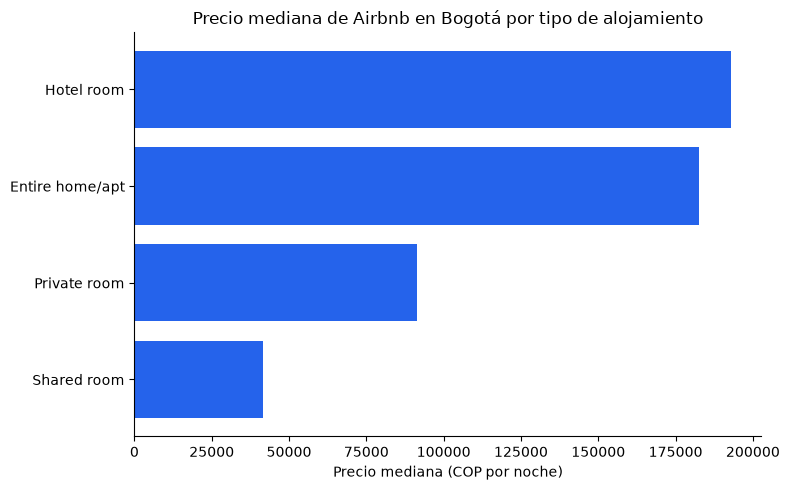

In [129]:
import matplotlib.pyplot as plt

precio_por_tipo = duckdb.sql("""
    SELECT room_type, MEDIAN(price_clean) AS precio_mediana, COUNT(*) AS cantidad
    FROM df_precio_limpio
    GROUP BY room_type
    ORDER BY precio_mediana DESC
""").df()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(precio_por_tipo['room_type'], precio_por_tipo['precio_mediana'], color='#2563eb')
ax.set_xlabel('Precio mediana (COP por noche)')
ax.set_title('Precio mediana de Airbnb en Bogotá por tipo de alojamiento')
ax.invert_yaxis()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('img/chart1_precio_room_type.png', dpi=150, bbox_inches='tight')
plt.show()

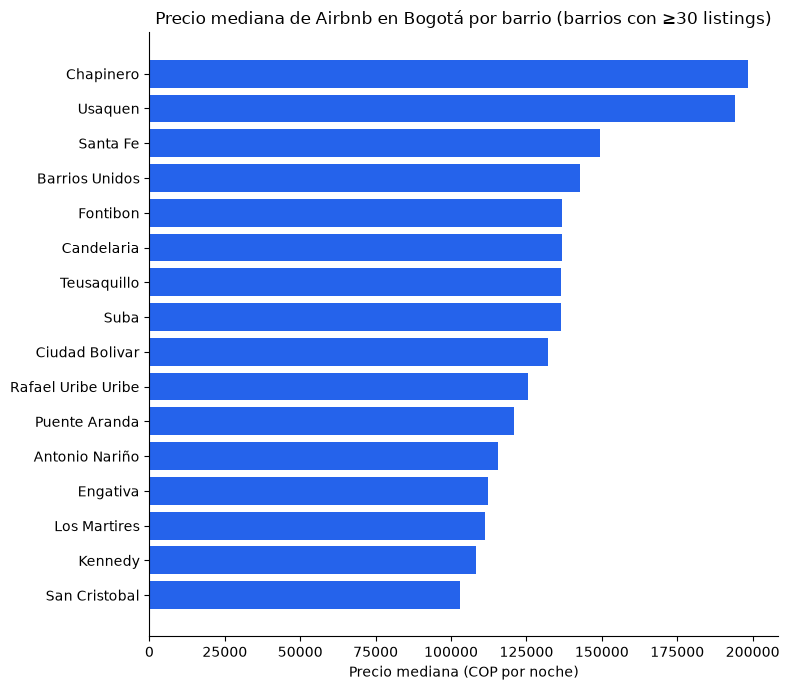

In [130]:
precio_por_barrio = duckdb.sql("""
    SELECT neighbourhood_cleansed, MEDIAN(price_clean) AS precio_mediana, COUNT(*) AS cantidad
    FROM df_precio_limpio
    WHERE neighbourhood_cleansed IN (SELECT neighbourhood_cleansed FROM barrios_confiables)
    GROUP BY neighbourhood_cleansed
    ORDER BY precio_mediana DESC
""").df()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(precio_por_barrio['neighbourhood_cleansed'], precio_por_barrio['precio_mediana'], color='#2563eb')
ax.set_xlabel('Precio mediana (COP por noche)')
ax.set_title('Precio mediana de Airbnb en Bogotá por barrio (barrios con ≥30 listings)')
ax.invert_yaxis()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('img/chart2_precio_barrio.png', dpi=150, bbox_inches='tight')
plt.show()

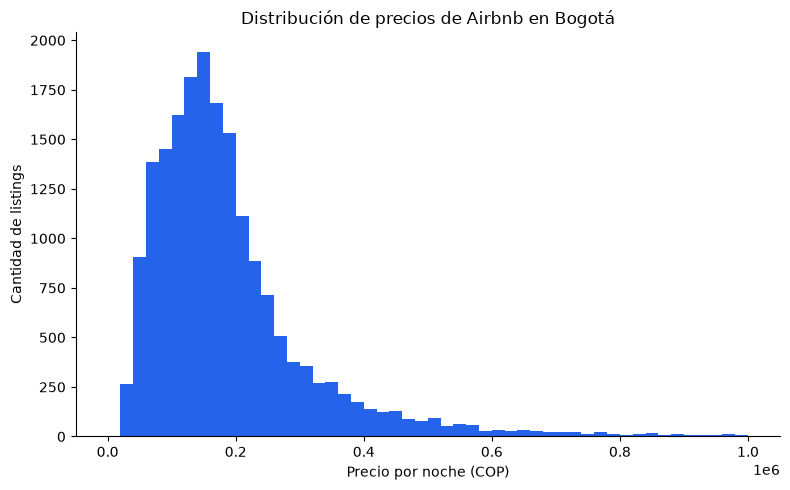

In [131]:
fig, ax = plt.subplots(figsize=(8, 5))

# range=(0, 1_000_000) le dice a hist() que calcule las 50 cajitas
# SOLO dentro de ese rango -- así cada cajita es más angosta y se ve más detalle
# (antes, las 50 cajitas cubrían todo hasta 5,000,000, y solo veíamos un pedacito)
ax.hist(df_precio_limpio['price_clean'], bins=50, range=(0, 1_000_000), color='#2563eb')

ax.set_xlabel('Precio por noche (COP)')
ax.set_ylabel('Cantidad de listings')
ax.set_title('Distribución de precios de Airbnb en Bogotá')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('img/chart3_distribucion_precios.png', dpi=150, bbox_inches='tight')
plt.show()

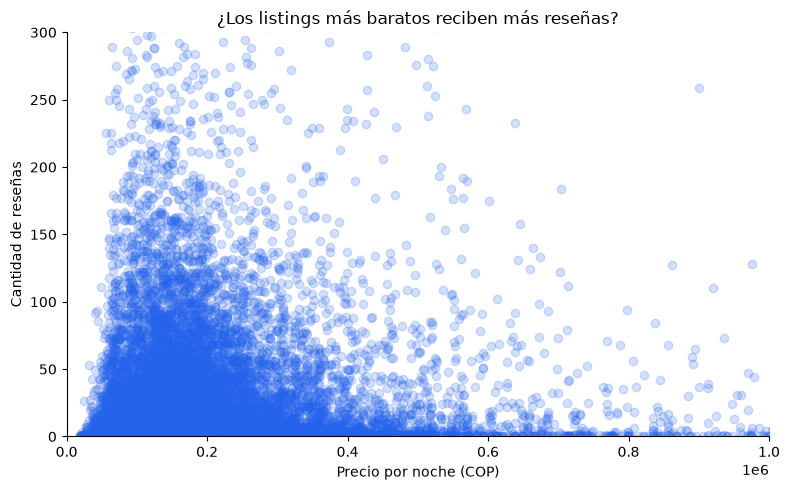

In [132]:
# preparamos los datos: precio limpio + reseñas, tratando los NULL como 0 con COALESCE
precio_vs_reviews = duckdb.sql("""
    SELECT price_clean, COALESCE(num_reviews, 0) AS num_reviews
    FROM resultado_left
""").df()

fig, ax = plt.subplots(figsize=(8, 5))

# scatter: cada punto es un listing. alpha=0.2 hace los puntos semi-transparentes
# para poder ver dónde se amontonan muchos (sobreplot)
ax.scatter(precio_vs_reviews['price_clean'], precio_vs_reviews['num_reviews'], alpha=0.2, color='#2563eb')

ax.set_xlabel('Precio por noche (COP)')
ax.set_ylabel('Cantidad de reseñas')
ax.set_title('¿Los listings más baratos reciben más reseñas?')

# recortamos la VISTA (no recalculamos nada) para que el outlier conocido
# (72Hub, 6,162 reseñas) no aplaste la escala y se pueda ver el resto de puntos
ax.set_xlim(0, 1_000_000)
ax.set_ylim(0, 300)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

# guardamos ANTES de mostrar — mismo nombre que ya usé en el README
plt.savefig('img/chart4_precio_vs_reviews.png', dpi=150, bbox_inches='tight')
plt.show()

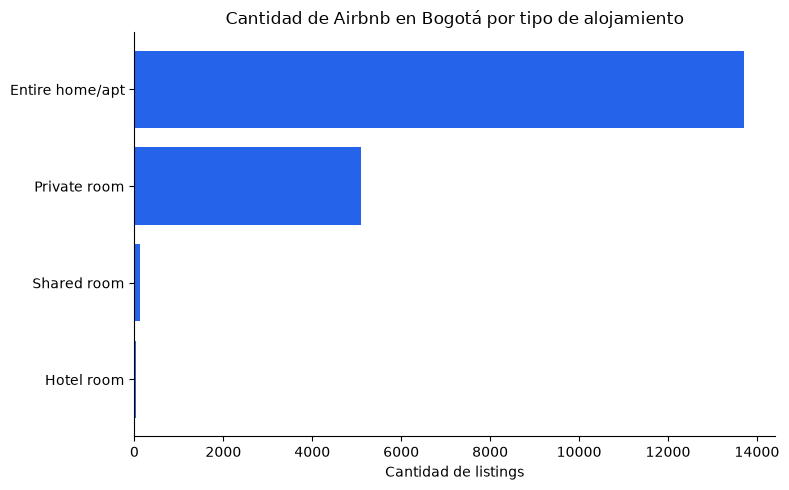

In [133]:
# contamos cuántos listings hay de cada room_type (composición del mercado)
cantidad_por_tipo = duckdb.sql("""
    SELECT room_type, COUNT(*) AS cantidad
    FROM df_precio_limpio
    GROUP BY room_type
    ORDER BY cantidad DESC
""").df()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cantidad_por_tipo['room_type'], cantidad_por_tipo['cantidad'], color='#2563eb')
ax.set_xlabel('Cantidad de listings')
ax.set_title('Cantidad de Airbnb en Bogotá por tipo de alojamiento')
ax.invert_yaxis()  # para que el más grande quede arriba
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

plt.savefig('img/chart5_cantidad_room_type.png', dpi=150, bbox_inches='tight')
plt.show()

In [134]:
# lista el contenido de la carpeta img/ con tamaños de archivo,
# para confirmar que las 5 imágenes se guardaron correctamente
!ls -la img/

total 492
drwxr-xr-x 2 dandelion dandelion   4096 Nov 16 15:51 .
drwxr-xr-x 5 dandelion dandelion   4096 Nov 16 15:50 ..
-rw-r--r-- 1 dandelion dandelion  36406 Nov 16 15:51 chart1_precio_room_type.png
-rw-r--r-- 1 dandelion dandelion  70077 Nov 16 15:51 chart2_precio_barrio.png
-rw-r--r-- 1 dandelion dandelion  39036 Nov 16 15:51 chart3_distribucion_precios.png
-rw-r--r-- 1 dandelion dandelion 308884 Nov 16 15:51 chart4_precio_vs_reviews.png
-rw-r--r-- 1 dandelion dandelion  32643 Nov 16 15:51 chart5_cantidad_room_type.png


In [135]:
# rango típico de precios: percentiles para describir dónde se concentra la mayoría
df_precio_limpio['price_clean'].describe()

count    1.895400e+04
mean     2.096759e+05
std      2.286898e+05
min      1.918111e+04
25%      1.096879e+05
50%      1.610050e+05
75%      2.295936e+05
max      4.716000e+06
Name: price_clean, dtype: float64

In [136]:
# porcentaje de listings sin ninguna reseña (usando el LEFT JOIN que ya tienes)
porcentaje_sin_reviews = (sin_reviews / len(resultado_left)) * 100
porcentaje_sin_reviews

21.757940276458797

In [140]:
# confirma que el README está ahí antes de copiarlo
!ls /mnt/c/Users/Lenovo/Downloads/ | grep -i readme

README.md


In [142]:
!cp "/mnt/c/Users/Lenovo/Downloads/README.md" ~/proyectos/airbnb-bogota/README.md

In [143]:
# verifica que el README quedó en la carpeta del proyecto
!ls -la ~/proyectos/airbnb-bogota/README.md

-rwxr-xr-x 1 dandelion dandelion 7098 Nov 16 16:10 /home/dandelion/proyectos/airbnb-bogota/README.md


In [144]:
# nos movemos a la carpeta del proyecto (todo lo que sigue corre desde ahí)
%cd ~/proyectos/airbnb-bogota

# inicializa git en esta carpeta
!git init

# .gitignore: le dice a git qué NO subir — el entorno virtual (pesa mucho),
# los datos crudos (Inside Airbnb los sigue publicando, no hace falta duplicarlos)
# y archivos temporales de Jupyter
!cat > .gitignore << 'EOF'
venv/
*.csv
*.csv.gz
.ipynb_checkpoints/
__pycache__/
EOF

SyntaxError: invalid syntax (468300688.py, line 11)

In [145]:
%cd ~/proyectos/airbnb-bogota

/home/dandelion/proyectos/airbnb-bogota


In [146]:
!git init

hint: Using 'master' as the name for the initial branch. This default branch name
hint: will change to "main" in Git 3.0. To configure the initial branch name
hint: to use in all of your new repositories, which will suppress this warning,
hint: call:
hint:
hint: 	git config --global init.defaultBranch <name>
hint:
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint:
hint: 	git branch -m <name>
hint:
hint: Disable this message with "git config set advice.defaultBranchName false"
Initialized empty Git repository in /home/dandelion/proyectos/airbnb-bogota/.git/


In [147]:
%%writefile .gitignore
# entorno virtual - pesa mucho, cada quien crea el suyo con pip install
venv/
# datos crudos - Inside Airbnb los sigue publicando, no hace falta duplicarlos en el repo
*.csv
*.csv.gz
# archivos temporales de Jupyter
.ipynb_checkpoints/
__pycache__/

Writing .gitignore


In [148]:
!cat .gitignore
!git status

# entorno virtual - pesa mucho, cada quien crea el suyo con pip install
venv/
# datos crudos - Inside Airbnb los sigue publicando, no hace falta duplicarlos en el repo
*.csv
*.csv.gz
# archivos temporales de Jupyter
.ipynb_checkpoints/
__pycache__/
On branch master

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	README.md
	analisis-airbnb-bogota.ipynb
	img/

nothing added to commit but untracked files present (use "git add" to track)
